Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [1]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features_4_gpt-4.1_freeform.csv"
MODEL_TAG    = "gpt-4.1-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features_4_gpt-4.1_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-4.1-freeform


## 1. Load & Inspect

In [2]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 199)
Feature cols : ['num_atoms', 'num_heavy_atoms', 'num_hydrogen_atoms', 'num_carbons', 'num_nitrogens', 'num_oxygens', 'num_sulfurs', 'num_phosphorus', 'num_fluorines', 'num_chlorines', 'num_bromines', 'num_iodines', 'num_rings', 'num_aromatic_rings', 'num_aliphatic_rings', 'num_heteroaromatic_rings', 'num_heterocycles', 'num_rotatable_bonds', 'num_amide_bonds', 'num_lactam_bonds', 'num_lactone_bonds', 'num_hba', 'num_hbd', 'num_primary_amines', 'num_secondary_amines', 'num_tertiary_amines', 'num_amidines', 'num_imines', 'num_amides', 'num_carboxylic_acids', 'num_ester_groups', 'num_ether_groups', 'num_alcohol_groups', 'num_phenol_groups', 'num_thiol_groups', 'num_disulfide_bonds', 'num_quaternary_ammonium', 'num_basic_nitrogens', 'num_acidic_nitrogens', 'num_basic_oxygens', 'num_acidic_oxygens', 'num_nitro_groups', 'num_nitrile_groups', 'num_guanidine_groups', 'num_urea_groups', 'num_sulfonamide_groups', 'num_sulfonic_acids', 'num_sulfoxides', 'num_sulfones', 

,num_atoms,num_heavy_atoms,num_hydrogen_atoms,num_carbons,num_nitrogens,num_oxygens,num_sulfurs,num_phosphorus,num_fluorines,num_chlorines,...,num_ring_imidazole_like_scaffolds,num_ring_nucleobase_like_scaffolds,num_ring_polycyclic_features,num_ring_flat_features,num_ring_flexible_features,num_ring_rigid_features,input,prestwick_ID,smiles_resolution,num_molecular_weight
0,11,9,2,0,6,1,0,0,0,0,...,1,1,1,1,0,1,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast,NaN
1,18,12,6,6,4,2,1,0,0,0,...,0,0,0,1,0,1,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast,NaN
2,27,21,6,13,3,3,1,0,0,0,...,0,1,1,1,0,1,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast,NaN


In [3]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                dtype  nulls
num_atoms                       int64      0
num_heavy_atoms                 int64      0
num_hydrogen_atoms              int64      0
num_carbons                     int64      0
num_nitrogens                   int64      0
...                               ...    ...
num_ring_polycyclic_features    int64      0
num_ring_flat_features          int64      0
num_ring_flexible_features      int64      0
num_ring_rigid_features         int64      0
num_molecular_weight          float64   1168

[196 rows x 2 columns]


,num_atoms,num_heavy_atoms,num_hydrogen_atoms,num_carbons,num_nitrogens,num_oxygens,num_sulfurs,num_phosphorus,num_fluorines,num_chlorines,...,num_ring_purine_like_scaffolds,num_ring_pyrimidine_like_scaffolds,num_ring_pyrrole_like_scaffolds,num_ring_imidazole_like_scaffolds,num_ring_nucleobase_like_scaffolds,num_ring_polycyclic_features,num_ring_flat_features,num_ring_flexible_features,num_ring_rigid_features,num_molecular_weight
count,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,...,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,29.000
mean,34.554,24.635,12.328,17.032,2.252,3.123,0.276,0.017,0.165,0.215,...,0.069,0.188,0.094,0.035,0.129,0.525,1.049,0.228,1.687,341.724
std,17.113,11.959,9.509,8.795,2.016,3.127,0.639,0.157,0.646,0.583,...,0.257,0.391,0.297,0.184,0.341,0.526,0.785,0.495,2.578,163.602
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,142.180
25%,24.000,17.000,7.000,11.000,1.000,1.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,273.340
50%,32.000,23.000,9.000,16.000,2.000,2.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,1.000,327.780
75%,38.000,29.000,13.000,21.000,3.000,4.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,2.000,367.200
max,143.000,104.000,78.000,66.000,18.000,24.000,10.000,2.000,7.000,6.000,...,2.000,1.000,2.000,1.000,2.000,2.000,12.000,8.000,30.000,1107.900





In [4]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [5]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 8
  molecular_weight                           -> MolWt
  num_hydrogen_bond_donors                   -> NumHDonors
  num_hydrogen_bond_acceptors                -> NumHAcceptors
  num_aromatic_rings                         -> NumAromaticRings
  num_rings                                  -> NumRings
  topological_polar_surface_area             -> TPSA
  fraction_csp3                              -> FractionCSP3
  num_rotatable_bonds                        -> NumRotatableBonds


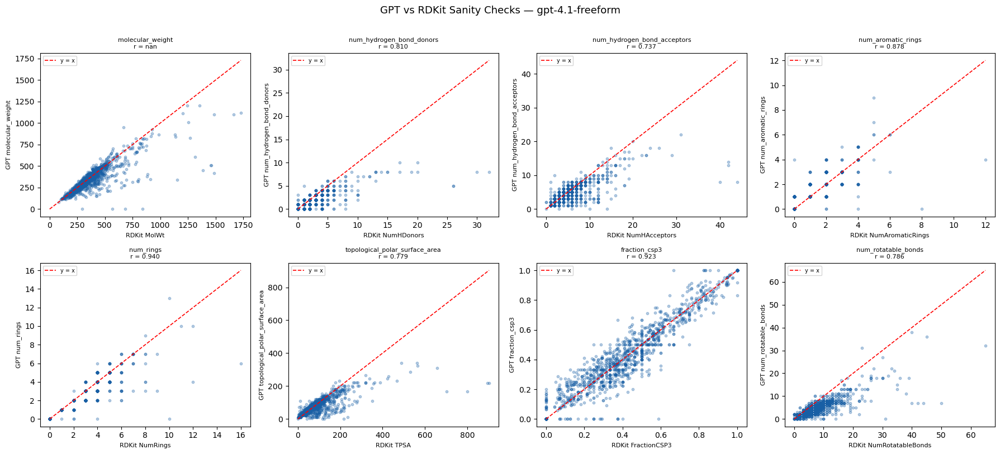

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1069,153.137,153.140,0.0
1,Prestw-1162,212.230,212.230,-0.0
2,Prestw-1207,180.159,180.158,-0.0
3,Prestw-1261,273.719,273.720,0.0
4,Prestw-1268,124.139,124.137,-0.0



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1036,666.910,950.18,283.27
1,Prestw-1034,572.875,704.01,131.13
2,Prestw-388,456.678,584.85,128.17
3,Prestw-1242,393.443,510.52,117.08
4,Prestw-837,568.751,676.97,108.22



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-160,1488.807,419.50,-1069.31
1,Prestw-159,1461.429,507.43,-954.00
2,Prestw-321,1457.397,507.46,-949.94
3,Prestw-506,1385.461,447.50,-937.96
4,Prestw-455,841.068,0.00,-841.07


In [6]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

## 3. Cross-Correlation: RDKit vs Freeform GPT

RDKit: 96 features  |  GPT freeform: 196 features





In [7]:
rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

# Compute only the GPT × RDKit cross-correlation block
combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr   # keep for novelty cell downstream

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]

# Clean axis labels (remove prefixes)
cross_block.index   = [c.replace("gpt__", "")   for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

fig, ax = plt.subplots(figsize=(max(20, n_rdkit * 0.22), max(4, n_gpt * 0.55)))
sns.heatmap(cross_block, cmap="coolwarm", center=0, annot=(n_gpt <= 30),
            fmt=".2f", linewidths=0.3, rasterized=True, ax=ax)
ax.set_title(f"Cross-Correlation: GPT freeform vs RDKit (Spearman) — {MODEL_TAG}", fontsize=12)
ax.set_xlabel("RDKit features", fontsize=10)
ax.set_ylabel("GPT freeform features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
corr_self  = gpt_al.corr(method="spearman")
gpt_labels = [c.replace("gpt__", "") for c in gpt_al.columns]

fig, ax = plt.subplots(figsize=(max(8, n_gpt), max(7, n_gpt - 1)))
sns.heatmap(corr_self, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=gpt_labels, yticklabels=gpt_labels, linewidths=0.4, ax=ax)
ax.set_title(f"GPT Feature Self-Correlation (Spearman) — {MODEL_TAG}", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "self_corr.png", dpi=150, bbox_inches="tight")
plt.show()




,gpt_feature,max_r_vs_rdkit,closest_rdkit
35,num_disulfide_bonds,0.060450,SMR_VSA10
39,num_basic_oxygens,0.066671,PEOE_VAS4
50,num_metal_atoms,0.076545,PEOE_VAS14
138,num_tetrazole_like_scaffolds,0.084356,SMR_VSA3
46,num_sulfonic_acids,0.090414,MolLogP
...,...,...,...
14,num_aliphatic_rings,0.898946,NumAliphaticRings
157,num_ring_atoms,0.911524,RingCount
16,num_heterocycles,0.915406,NumHeterocycles
73,fraction_csp3,0.923026,FractionCSP3


In [9]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

## 4. Build Feature Matrix

In [10]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

Feature matrix: (1197, 197)  (196 -> 196 features)


In [11]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")

Pairs: (47880, 4)  |  label dist: {0: 41338, 1: 6542}
After merge: (47880, 200)  |  unmatched compounds: 0
